<a href="https://colab.research.google.com/github/ryanlin3124/Pytorch-exercises/blob/main/imaging_exercises/imaging_classification/BrainTumorClassification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Brain Tumor classification
Will be using the brain tumor data from Mendeley Data: https://data.mendeley.com/datasets/zwr4ntf94j/1

The goal will be to classify the 4 seperate "tumors", those being:

- Glioma
- Pituitary
- Meningioma
- No Tumor

In [26]:
# mount google drive
from google.colab import drive

drive.mount('/content/drive')

dataset_path = '/content/drive/MyDrive/Epic and CSCR hospital Dataset.zip'


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [27]:
# verify that the dataset was obtained
import os
if os.path.exists(dataset_path):
    print("Folder found")
else:
    print("Folder not found")

# File structure: Epic and CSCR hospital Dataset - Training/Testing - The 4 Tumor (each are seperate files) - Images

Folder found


In [28]:
import torch
from torch import nn
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import zipfile
from pathlib import Path

# Setup device agnostic code

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using {device}")

Using cuda


In [29]:
data_path = Path(dataset_path)
# Extract to Colab's local directory
dataset = Path("/content/dataset")

# with zipfile.ZipFile(data_path, "r") as zip_ref:
#    zip_ref.extractall(dataset)

# Safely keep the zip file on Google Drive to avoid deleting your source dataset
# os.remove(data_path)

In [30]:
# Peek into the data to verify
def walk_through_dir(dir_path):
    for dirpath, dirnames, filenames in os.walk(dir_path):
        print(f"There are {len(dirnames)} directories and {len(filenames)} images in '{dirpath}'.")

walk_through_dir(dataset)

There are 1 directories and 0 images in '/content/dataset'.
There are 2 directories and 0 images in '/content/dataset/Epic and CSCR hospital Dataset'.
There are 4 directories and 0 images in '/content/dataset/Epic and CSCR hospital Dataset/Test'.
There are 0 directories and 546 images in '/content/dataset/Epic and CSCR hospital Dataset/Test/meningioma'.
There are 0 directories and 487 images in '/content/dataset/Epic and CSCR hospital Dataset/Test/notumor'.
There are 0 directories and 626 images in '/content/dataset/Epic and CSCR hospital Dataset/Test/pituitary'.
There are 0 directories and 755 images in '/content/dataset/Epic and CSCR hospital Dataset/Test/glioma'.
There are 4 directories and 0 images in '/content/dataset/Epic and CSCR hospital Dataset/Train'.
There are 0 directories and 2183 images in '/content/dataset/Epic and CSCR hospital Dataset/Train/meningioma'.
There are 0 directories and 1945 images in '/content/dataset/Epic and CSCR hospital Dataset/Train/notumor'.
There are

Image shape: (224, 224)


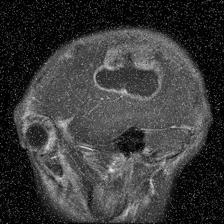

In [31]:
# Let's visualize some data, pull up some random photo
import random
from PIL import Image

SEED = 42

random.seed(SEED)

img_path_list = list(dataset.glob("*/*/*/*.jpg"))
img_path = random.choice(img_path_list)

img = Image.open(img_path)
print(f"Image shape: {img.size}")
# print(f"Image path: {img_path_list}")
img


In [32]:
# Transform the data into tensors and prep the data
data_transform = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ToTensor()
])

# set a training and testing path
train_path = dataset / "Epic and CSCR hospital Dataset" / "Train"
test_path = dataset / "Epic and CSCR hospital Dataset" / "Test"

train_data = datasets.ImageFolder(root=train_path, transform=data_transform, target_transform=None)
test_data = datasets.ImageFolder(root=test_path, transform=data_transform)

print(f"Train data: {train_data}, Test data: {test_data}")

Train data: Dataset ImageFolder
    Number of datapoints: 9650
    Root location: /content/dataset/Epic and CSCR hospital Dataset/Train
    StandardTransform
Transform: Compose(
               Resize(size=(64, 64), interpolation=bilinear, max_size=None, antialias=True)
               ToTensor()
           ), Test data: Dataset ImageFolder
    Number of datapoints: 2414
    Root location: /content/dataset/Epic and CSCR hospital Dataset/Test
    StandardTransform
Transform: Compose(
               Resize(size=(64, 64), interpolation=bilinear, max_size=None, antialias=True)
               ToTensor()
           )


In [33]:
# Set classes
class_name = train_data.classes
print(class_name)

class_dict = train_data.class_to_idx
print(class_dict)

['glioma', 'meningioma', 'notumor', 'pituitary']
{'glioma': 0, 'meningioma': 1, 'notumor': 2, 'pituitary': 3}


Image: tensor([[[0.1569, 0.1569, 0.1608,  ..., 0.1569, 0.1569, 0.1569],
         [0.1569, 0.1569, 0.1569,  ..., 0.1608, 0.1569, 0.1569],
         [0.1569, 0.1569, 0.1569,  ..., 0.1569, 0.1569, 0.1569],
         ...,
         [0.1569, 0.1569, 0.1569,  ..., 0.1529, 0.1569, 0.1569],
         [0.1569, 0.1569, 0.1608,  ..., 0.1569, 0.1569, 0.1569],
         [0.1569, 0.1569, 0.1569,  ..., 0.1569, 0.1569, 0.1569]],

        [[0.1569, 0.1569, 0.1608,  ..., 0.1569, 0.1569, 0.1569],
         [0.1569, 0.1569, 0.1569,  ..., 0.1608, 0.1569, 0.1569],
         [0.1569, 0.1569, 0.1569,  ..., 0.1569, 0.1569, 0.1569],
         ...,
         [0.1569, 0.1569, 0.1569,  ..., 0.1529, 0.1569, 0.1569],
         [0.1569, 0.1569, 0.1608,  ..., 0.1569, 0.1569, 0.1569],
         [0.1569, 0.1569, 0.1569,  ..., 0.1569, 0.1569, 0.1569]],

        [[0.1569, 0.1569, 0.1608,  ..., 0.1569, 0.1569, 0.1569],
         [0.1569, 0.1569, 0.1569,  ..., 0.1608, 0.1569, 0.1569],
         [0.1569, 0.1569, 0.1569,  ..., 0.1569, 0.1

Text(0.5, 1.0, 'glioma')

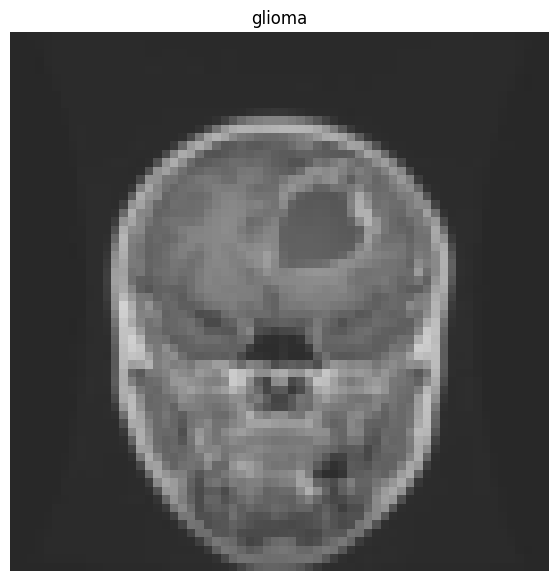

In [34]:
import matplotlib.pyplot as plt

# Visualize the data

img, label = train_data[0][0], test_data[0][1]
print(f"Image: {img}")
print(f"Image Shape:{img.shape}")
print(f"Img type: {img.dtype}")
print(f"Label: {label}")
print(f"Label type: {type(label)}")

# since img shape is organized like [C,H,W] and matplotlib prefers [H,W,C], rearrange it
img_permute = img.permute(1, 2, 0)

# The data will be more pixeled since transforming from it original size to 64X64 reduced pixels
plt.figure(figsize=(10, 7))
plt.imshow(img_permute)
plt.axis("off")
plt.title(class_name[label])

In [35]:
# Create the dataloaders
BATCH = 32
WORKERS = os.cpu_count()

train_dataloader = DataLoader(dataset=train_data, batch_size=BATCH, shuffle=True, num_workers=WORKERS)
test_dataloader = DataLoader(dataset=test_data, batch_size=BATCH, shuffle=False, num_workers=WORKERS)

train_dataloader, test_dataloader, WORKERS

(<torch.utils.data.dataloader.DataLoader at 0x7f1b523e0690>,
 2)

In [41]:
class TinyVGG(nn.Module):
  def __init__(self, input_shape: int, hidden_units: int, output_shape: int):
    super().__init__()
    self.conv_block_1 = nn.Sequential(
        nn.Conv2d(in_channels=input_shape, out_channels=hidden_units, kernel_size=3, stride=1, padding=1),
        nn.ReLU(),
        nn.Conv2d(in_channels=hidden_units, out_channels=hidden_units, kernel_size=3, stride=1, padding=1),
        nn.ReLU(),
        nn.MaxPool2d(kernel_size=2, stride=2)
    )
    self.conv_block_2 = nn.Sequential(
        nn.Conv2d(in_channels=hidden_units, out_channels=hidden_units, kernel_size=3, padding=1),
        nn.ReLU(),
        nn.Conv2d(in_channels=hidden_units, out_channels=hidden_units, kernel_size=3, padding=1),
        nn.ReLU(),
        nn.MaxPool2d(2)
    )
    self.classifer = nn.Sequential(
        nn.Flatten(),
        nn.Linear(in_features=hidden_units*16*16, out_features=output_shape)
    )

  def forward(self, x:torch.Tensor):
    x = self.conv_block_1(x)
    x = self.conv_block_2(x)
    x = self.classifer(x)
    return x

torch.manual_seed(SEED)
model_0 = TinyVGG(input_shape=3, hidden_units=10, output_shape=len(class_name)).to(device)
model_0

TinyVGG(
  (conv_block_1): Sequential(
    (0): Conv2d(3, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU()
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (conv_block_2): Sequential(
    (0): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU()
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifer): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=2560, out_features=4, bias=True)
  )
)

In [45]:
# Create the train and test function
def train_step(model: torch.nn.Module,
          dataloader: torch.utils.data.DataLoader,
          loss_fn: torch.nn.Module,
          optim: torch.optim.Optimizer):
  # put model in train mode
  model.train()

  # setup loss and accuracy
  train_loss, train_acc = 0, 0

  for batch, (X, y) in enumerate(dataloader):
    # send data to target device
    X, y = X.to(device), y.to(device)

    # forward pass
    y_pred = model(X)

    # calculate loss
    loss = loss_fn(y_pred, y)
    train_loss += loss.item()

    # optimizer zero grad
    optim.zero_grad()

    # loss backward
    loss.backward()

    # optimizer step
    optim.step()

    # calculate accuracy
    y_pred_class = torch.argmax(torch.softmax(y_pred, dim=1), dim=1)
    train_acc += (y_pred_class == y).sum().item()/len(y_pred)

  # Adjust metrics
  train_loss = train_loss / len(dataloader)
  train_acc = train_acc / len(dataloader)
  print(f"Train loss: {train_loss:.5f} | Train accuracy: {train_acc:.2f}%")
  return train_loss, train_acc

def test_step(model: torch.nn.Module,
              dataloader: torch.utils.data.DataLoader,
              loss_fn: torch.nn.Module):
  # put model in eval mode
  model.eval()

  # setup loss and accuracy
  test_loss, test_acc = 0, 0

  with torch.inference_mode():
    for batch, (X,y) in enumerate(dataloader):
      # send data to target device
      X, y = X.to(device), y.to(device)

      # forward pass
      test_pred = model(X)

      # calculate loss
      loss = loss_fn(test_pred, y)
      test_loss += loss.item()

      # calc acc
      test_pred_label = test_pred.argmax(dim=1)
      test_acc += (test_pred_label == y).sum().item()/len(test_pred_label)

    # Adjust metrics
    test_loss = test_loss / len(dataloader)
    test_acc = test_acc / len(dataloader)
    print(f"Test loss: {test_loss:.5f} | Test accuracy: {test_acc:.2f}%\n")
    return test_loss, test_acc

In [46]:
epochs = 5
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(params=model_0.parameters(), lr=0.001)

for epoch in range(epochs):
  train_step(model=model_0, dataloader=train_dataloader, loss_fn=loss_fn, optim=optimizer)
  test_step(model=model_0, dataloader=test_dataloader, loss_fn=loss_fn)

Train loss: 0.47872 | Train accuracy: 0.83%
Test loss: 0.61514 | Test accuracy: 0.77%

Train loss: 0.41662 | Train accuracy: 0.85%
Test loss: 0.57082 | Test accuracy: 0.78%

Train loss: 0.35360 | Train accuracy: 0.87%
Test loss: 0.63807 | Test accuracy: 0.78%

Train loss: 0.30686 | Train accuracy: 0.89%
Test loss: 0.53576 | Test accuracy: 0.81%

Train loss: 0.26318 | Train accuracy: 0.91%
Test loss: 0.57301 | Test accuracy: 0.81%

